# Bassac River Forecasting — Part 2: Station Calibration & Feature Engineering

Calibrates Koh Khel onto the Koh Thum scale (2020–2023 overlap), merges all 4 daily tables, builds 10 leak-free features, and verifies zero leakage.

In [1]:
# ==============================================================================
# SETUP & LOAD CLEANED DAILY TABLES
# ==============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED_DIR = Path('..').resolve() / 'data' / 'processed'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

bassac = pd.read_csv(PROCESSED_DIR / 'bassac_daily.csv', parse_dates=['date']).sort_values('date')
kohkhel = pd.read_csv(PROCESSED_DIR / 'kohkhel_daily.csv', parse_dates=['date']).sort_values('date')
glofas = pd.read_csv(PROCESSED_DIR / 'glofas_daily.csv', parse_dates=['date']).sort_values('date')
rainfall = pd.read_csv(PROCESSED_DIR / 'nasa_rain_daily.csv', parse_dates=['date']).sort_values('date')

print('Loaded tables:', len(bassac), 'bassac |', len(kohkhel), 'kohkhel |', len(glofas), 'glofas |', len(rainfall), 'rainfall')


Loaded tables: 1438 bassac | 1511 kohkhel | 2353 glofas | 2363 rainfall


Shared days (2020-2023): 643
Correlation (r)        : 0.9957
Calibration formula    : WL = 0.7942 * WL_raw + (-0.4756)
Average gap (MAE)      : 1.482 m -> 0.093 m


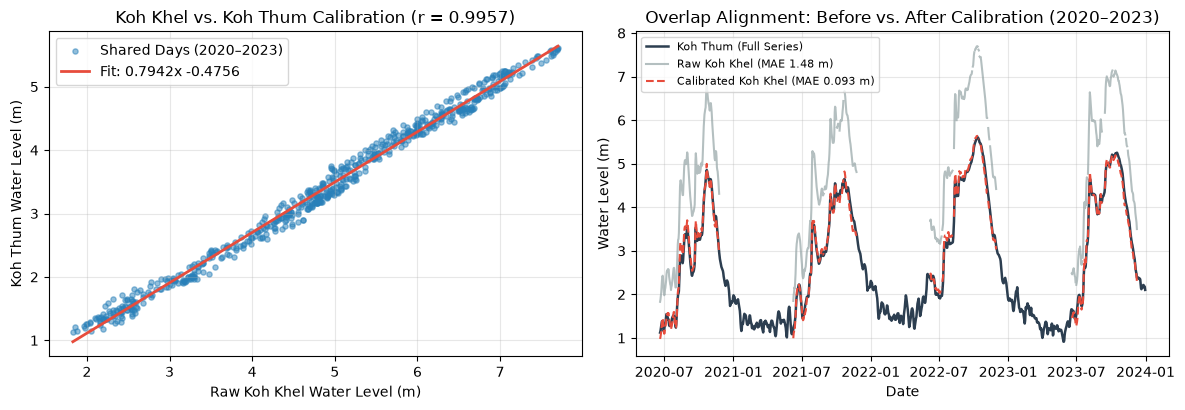

In [2]:
# ==============================================================================
# FIT STATION CALIBRATION ON 2020 - 2023 OVERLAP (NO 2024 - 2026 LEAKAGE)
# ==============================================================================
overlap = bassac.dropna(subset=['WL']).merge(kohkhel, on='date', how='inner')
correlation_r = overlap['WL'].corr(overlap['WL_raw'])
slope, intercept = np.polyfit(overlap['WL_raw'], overlap['WL'], 1)
overlap['WL_calibrated'] = slope * overlap['WL_raw'] + intercept

mae_before = (overlap['WL_raw'] - overlap['WL']).abs().mean()
mae_after = (overlap['WL_calibrated'] - overlap['WL']).abs().mean()

print(f'Shared days (2020-2023): {len(overlap)}')
print(f'Correlation (r)        : {correlation_r:.4f}')
print(f'Calibration formula    : WL = {slope:.4f} * WL_raw + ({intercept:.4f})')
print(f'Average gap (MAE)      : {mae_before:.3f} m -> {mae_after:.3f} m')

# ==============================================================================
# PLOT CALIBRATION SCATTER & BEFORE / AFTER ALIGNMENT
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].scatter(overlap['WL_raw'], overlap['WL'], alpha=0.5, s=14, color='#2980b9', label='Shared Days (2020–2023)')
x_line = np.linspace(overlap['WL_raw'].min(), overlap['WL_raw'].max(), 100)
axes[0].plot(x_line, slope * x_line + intercept, color='#e74c3c', linewidth=2, label=f'Fit: {slope:.4f}x {intercept:+.4f}')
axes[0].set_title(f'Koh Khel vs. Koh Thum Calibration (r = {correlation_r:.4f})')
axes[0].set_xlabel('Raw Koh Khel Water Level (m)')
axes[0].set_ylabel('Koh Thum Water Level (m)')
axes[0].legend()

overlap_daily = overlap.set_index('date')[['WL', 'WL_raw', 'WL_calibrated']].asfreq('D')
bassac_full_line = bassac[bassac['date'] <= '2023-12-31'].set_index('date')['WL'].asfreq('D')
axes[1].plot(bassac_full_line.index, bassac_full_line.values, label='Koh Thum (Full Series)', color='#2c3e50', linewidth=1.8)
axes[1].plot(overlap_daily.index, overlap_daily['WL_raw'], label=f'Raw Koh Khel (MAE {mae_before:.2f} m)', color='#95a5a6', alpha=0.7)
axes[1].plot(overlap_daily.index, overlap_daily['WL_calibrated'], label=f'Calibrated Koh Khel (MAE {mae_after:.3f} m)', color='#e74c3c', linestyle='--')
axes[1].set_title('Overlap Alignment: Before vs. After Calibration (2020–2023)')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Water Level (m)')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


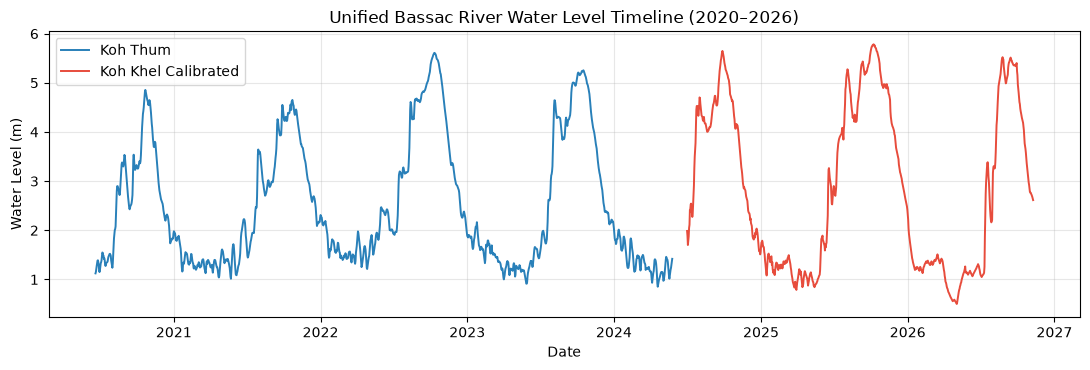

In [3]:
# ==============================================================================
# STITCH 2020 - 2026 WATER LEVEL & JOIN DISCHARGE + RAINFALL
# ==============================================================================
part_2020_2024 = bassac[['date', 'WL']].copy()
part_2020_2024['station_source'] = 'Koh_Thum'

part_2024_2026 = kohkhel[kohkhel['date'] >= pd.Timestamp('2024-07-01')].copy()
part_2024_2026['WL'] = slope * part_2024_2026['WL_raw'] + intercept
part_2024_2026['station_source'] = 'Koh_Khel_Calibrated'
part_2024_2026 = part_2024_2026[['date', 'WL', 'station_source']]

combined_wl = pd.concat([part_2020_2024, part_2024_2026], ignore_index=True)
end_date = min(combined_wl['date'].max(), glofas['date'].max(), rainfall['date'].max())
calendar_days = pd.DataFrame({'date': pd.date_range(combined_wl['date'].min(), end_date, freq='D')})

daily_table = (
    calendar_days
    .merge(combined_wl, on='date', how='left')
    .merge(glofas[['date', 'upstream_discharge']], on='date', how='left')
    .merge(rainfall[['date', 'rain_mm']], on='date', how='left')
    .sort_values('date')
    .reset_index(drop=True)
)

# ==============================================================================
# PLOT UNIFIED 2020 - 2026 WATER LEVEL TIMELINE
# ==============================================================================
fig, ax = plt.subplots(figsize=(11, 3.8))
for src_name, color in [('Koh_Thum', '#2980b9'), ('Koh_Khel_Calibrated', '#e74c3c')]:
    sub = daily_table[daily_table['station_source'] == src_name].set_index('date')['WL'].asfreq('D')
    ax.plot(sub.index, sub.values, label=src_name.replace('_', ' '), color=color, linewidth=1.4)
ax.set_title('Unified Bassac River Water Level Timeline (2020–2026)')
ax.set_xlabel('Date')
ax.set_ylabel('Water Level (m)')
ax.legend()
plt.tight_layout()
plt.show()


In [4]:
# ==============================================================================
# BUILD 10 PAST-ONLY FEATURES & 1-DAY-AHEAD TARGET (WL_next)
# ==============================================================================
FEATURE_COLS = [
    'WL', 'WL_lag1', 'WL_lag2', 'WL_lag3', 'WL_diff',
    'upstream_discharge_lag1', 'upstream_discharge_diff',
    'rain_mm', 'rain_lag1', 'rain_3d'
]
TARGET_COL = 'WL_next'

df_feat = daily_table.copy()
df_feat['WL_lag1'] = df_feat['WL'].shift(1)
df_feat['WL_lag2'] = df_feat['WL'].shift(2)
df_feat['WL_lag3'] = df_feat['WL'].shift(3)
df_feat['WL_diff'] = df_feat['WL'] - df_feat['WL_lag1']

df_feat['upstream_discharge_lag1'] = df_feat['upstream_discharge'].shift(1)
df_feat['upstream_discharge_diff'] = df_feat['upstream_discharge'] - df_feat['upstream_discharge_lag1']

df_feat['rain_lag1'] = df_feat['rain_mm'].shift(1)
df_feat['rain_3d'] = df_feat['rain_mm'].rolling(3).sum()

df_feat[TARGET_COL] = df_feat['WL'].shift(-1)

# Drop boundary rows around edges and June 2024 station gap (no synthetic interpolation)
modeling_table = df_feat.dropna(subset=FEATURE_COLS + [TARGET_COL]).reset_index(drop=True)
modeling_table = modeling_table[['date', 'station_source'] + FEATURE_COLS + [TARGET_COL]]
modeling_table.to_csv(PROCESSED_DIR / 'modeling_table.csv', index=False)

print('Saved modeling_table.csv:', modeling_table.shape)

# ==============================================================================
# ZERO-LEAKAGE & ALIGNMENT CHECKS
# ==============================================================================
assert len(FEATURE_COLS) == 10
assert modeling_table[FEATURE_COLS + [TARGET_COL]].isna().sum().sum() == 0

consec_idx = modeling_table.index[modeling_table['date'].diff().dt.days == 1]
for idx in consec_idx[:200]:
    assert abs(modeling_table.loc[idx - 1, TARGET_COL] - modeling_table.loc[idx, 'WL']) < 1e-6

train_max = modeling_table.loc[modeling_table['date'] <= '2024-05-26', 'date'].max()
test_min = modeling_table.loc[modeling_table['date'] > '2024-05-26', 'date'].min()
assert train_max < test_min

print('All zero-leakage & alignment checks PASSED.')
print(f'Train rows (2020-2024): {(modeling_table["date"] <= "2024-05-26").sum()} | Test rows (2024-2026): {(modeling_table["date"] > "2024-05-26").sum()}')


Saved modeling_table.csv: (2285, 13)
All zero-leakage & alignment checks PASSED.
Train rows (2020-2024): 1427 | Test rows (2024-2026): 858
